# RetailMind AI — Customer Churn Engine
## Consolidated project: Days 1–4

RetailMind AI is being built as one evolving retail analytics platform. This notebook develops its first churn-prediction capability in four increments:

1. **Day 1 — Baseline:** inspect the Telco dataset, prepare features, train a baseline model, evaluate it, and save a reusable inference pipeline.
2. **Day 2 — Model challengers:** compare Decision Tree, Random Forest, and SVM using the same data split and a consistent validation strategy.
3. **Day 3 — Optimisation:** tune candidate models with cross-validation, inspect learning curves, and select a champion using training-only validation results.
4. **Day 4 — Feature improvement and ensembles:** add interpretable customer features, apply feature selection, and compare ensemble models.

**Business objective:** identify customers likely to churn so the retention team can prioritise outreach.

**Positive class:** `Churn = Yes` (encoded as `1`). Recall for this class is important because false negatives represent customers who churn but were not flagged.

> Run the notebook from top to bottom the first time. Each day builds on objects created earlier. The notebook saves fitted pipelines and reports into the project folders.

## 0. Project setup

### Recommended folder structure

Create or extract the project so that it looks like this:

```text
RetailMind_AI/
│
├── data/
│   └── Telco-Customer-Churn.csv
│
├── notebooks/
│   └── RetailMind_Churn_Days_1_to_4.ipynb
│
├── models/                 # Saved fitted pipelines are written here
├── reports/                # Metrics tables and learning-curve output
├── src/                    # Later: reusable application/service code
├── README.md
├── requirements.txt
└── .gitignore
```

### Dataset

Download **Telco Customer Churn** from Kaggle:

https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Place the CSV in `data/`. The notebook accepts either common filename:
- `Telco-Customer-Churn.csv`
- `WA_Fn-UseC_-Telco-Customer-Churn.csv`

### Run in VS Code

1. Open the **RetailMind_AI** folder in VS Code (not just the notebook file).
2. Install the **Python** and **Jupyter** extensions if they are not already installed.
3. Open a terminal in the project folder and create/activate a virtual environment if desired.
4. Install dependencies from `requirements.txt`.
5. Open `notebooks/RetailMind_Churn_Days_1_to_4.ipynb`.
6. Select the Python kernel associated with the environment where the dependencies were installed.
7. Run cells individually with **Run Cell** or `Shift + Enter`. Use **Run All** only after the dataset path and kernel are correct.

If the notebook is moved outside the `notebooks/` folder, update `PROJECT_ROOT` in the next cell.

In [26]:
# Run this cell once after opening the notebook.
# It checks the project folders and locates the dataset.

from pathlib import Path
import os
import warnings

# The notebook is expected to live in RetailMind_AI/notebooks/.
# In VS Code, open the RetailMind_AI folder as the workspace.
NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == "notebooks":
    PROJECT_ROOT = NOTEBOOK_DIR.parent
elif (NOTEBOOK_DIR / "notebooks").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
else:
    # Fallback for environments where the current directory is not obvious.
    PROJECT_ROOT = NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

for folder in [DATA_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_CANDIDATES = [
    DATA_DIR / "Telco-Customer-Churn.csv",
    DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)

print("Project root:", PROJECT_ROOT)
print("Dataset folder:", DATA_DIR)
print("Models folder:", MODEL_DIR)
print("Reports folder:", REPORT_DIR)

if DATA_PATH is None:
    print("\nDataset not found yet. Download the Kaggle CSV and place it in data/.")
else:
    print("\nDataset found:", DATA_PATH.name)

Project root: /home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project
Dataset folder: /home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/data
Models folder: /home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/models
Reports folder: /home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/reports

Dataset found: Telco-Customer-Churn.csv


## 0.1 Install and import the required libraries

The core workflow uses `pandas`, `scikit-learn`, and `joblib`. `matplotlib` is used for the Day 3 learning curve. `xgboost` is optional and is only needed for the XGBoost experiment on Day 4.

If packages are missing, install them in the VS Code terminal using:

```bash
python -m pip install -r requirements.txt
```

In [27]:
import numpy as np
import pandas as pd
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    learning_curve,
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TARGET = "Churn"

print("Imports completed.")

Imports completed.


# Day 1 — Establish the baseline churn pipeline

**Goal:** create the first working churn model and save the entire preprocessing-plus-model workflow.

The Telco dataset contains both numeric and categorical columns. The preprocessing workflow will:
- convert `TotalCharges` to numeric (blank values become missing values);
- impute missing numeric values with the median;
- scale numeric columns;
- impute missing categorical values with the most frequent value;
- one-hot encode categorical columns.

These transformations are placed inside a `Pipeline` and `ColumnTransformer`. This is important: the transformations are fitted on training data only, which prevents information from the test set leaking into preprocessing.

### 1.1 Load and inspect the CSV

In [28]:
# Locate the CSV again in case the setup cell was run before the file was copied.
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Place the Kaggle CSV in the project's data/ folder. "
        "Expected Telco-Customer-Churn.csv or WA_Fn-UseC_-Telco-Customer-Churn.csv."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn data types:")
display(df.dtypes)
print("\nChurn distribution:")
display(df[TARGET].value_counts(dropna=False))
print("\nChurn proportions:")
display(df[TARGET].value_counts(normalize=True).round(3))

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column data types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn proportions:


Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

### 1.2 Clean the target and prepare features

In [29]:
# TotalCharges looks numeric but may contain blank strings in the original CSV.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# CustomerID is an identifier, not a behavioural predictor.
df = df.drop(columns=["customerID"], errors="ignore")

# Encode the target: No = 0, Yes = 1.
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})

if df[TARGET].isna().any():
    raise ValueError("Unexpected target labels. Expected only 'Yes' and 'No'.")

X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("\nMissing values by feature (non-zero only):")
display(X.isna().sum()[X.isna().sum() > 0])

Feature matrix: (7043, 19)
Target vector: (7043,)

Missing values by feature (non-zero only):


TotalCharges    11
dtype: int64

### 1.3 Create one fixed, stratified train/test split

In [30]:
# Keep the same split for all four days so that comparisons are consistent.
# Stratification preserves approximately the same churn proportion in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)
print("\nChurn rate — train:", round(y_train.mean(), 3))
print("Churn rate — test: ", round(y_test.mean(), 3))

X_train: (5634, 19)
X_test:  (1409, 19)
y_train: (5634,)
y_test:  (1409,)

Churn rate — train: 0.265
Churn rate — test:  0.265


### 1.4 Build reusable preprocessing

In [31]:
def make_preprocessor(input_frame):
    """Create numeric and categorical preprocessing based on input columns."""
    numeric_columns = input_frame.select_dtypes(include="number").columns.tolist()
    categorical_columns = input_frame.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])


def make_model_pipeline(input_frame, estimator, use_feature_selection=False):
    """Package preprocessing and an estimator into one fitted/persistable object."""
    steps = [("preprocess", make_preprocessor(input_frame))]

    if use_feature_selection:
        # k is set later based on the transformed feature count.
        steps.append(("feature_selection", SelectKBest(score_func=f_classif, k=30)))

    steps.append(("model", estimator))
    return Pipeline(steps)


print("Preprocessing and pipeline helper functions are ready.")

Preprocessing and pipeline helper functions are ready.


### 1.5 Train the Day 1 baseline model

In [32]:
# Logistic Regression is the Day 1 baseline.
# class_weight='balanced' asks the model to account for the unequal class counts.
baseline_pipeline = make_model_pipeline(
    X_train,
    LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
)

baseline_pipeline.fit(X_train, y_train)
print("Day 1 baseline pipeline fitted.")

Day 1 baseline pipeline fitted.


### 1.6 Evaluate the baseline

In [33]:
def evaluate_classifier(model_name, fitted_pipeline, features, target, show_details=True):
    """Calculate consistent metrics. Churn=Yes (1) is the positive class."""
    predictions = fitted_pipeline.predict(features)

    if hasattr(fitted_pipeline, "predict_proba"):
        continuous_scores = fitted_pipeline.predict_proba(features)[:, 1]
    else:
        continuous_scores = fitted_pipeline.decision_function(features)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(target, predictions),
        "Precision": precision_score(target, predictions, zero_division=0),
        "Recall": recall_score(target, predictions, zero_division=0),
        "F1": f1_score(target, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(target, continuous_scores),
    }

    if show_details:
        display(pd.DataFrame([metrics]).set_index("Model"))
        print("Confusion matrix [[TN, FP], [FN, TP]]:")
        print(confusion_matrix(target, predictions))
        print("\nClassification report:")
        print(classification_report(
            target,
            predictions,
            target_names=["No Churn", "Churn"],
            zero_division=0,
        ))

    return metrics


day1_metrics = evaluate_classifier(
    "Day 1 — Logistic Regression baseline",
    baseline_pipeline,
    X_test,
    y_test,
)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 1 — Logistic Regression baseline,0.738112,0.504303,0.783422,0.613613,0.841298


Confusion matrix [[TN, FP], [FN, TP]]:
[[747 288]
 [ 81 293]]

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



### 1.7 Persist the baseline pipeline

In [34]:
# Save the fitted preprocessing + classifier together.
day1_model_path = MODEL_DIR / "churn_day1_baseline.joblib"
joblib.dump(baseline_pipeline, day1_model_path)

# A small inference helper: new customer records go in; labels and probabilities come out.
def predict_churn(customer_rows, fitted_model=baseline_pipeline):
    """Predict churn label and churn probability for a DataFrame of customer records."""
    churn_labels = fitted_model.predict(customer_rows)
    churn_probabilities = fitted_model.predict_proba(customer_rows)[:, 1]

    return pd.DataFrame({
        "predicted_churn": churn_labels,
        "churn_probability": churn_probabilities,
    }, index=customer_rows.index)


print("Saved:", day1_model_path)
display(predict_churn(X_test.head()))

Saved: /home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/models/churn_day1_baseline.joblib


,predicted_churn,churn_probability
437,0,0.115472
2280,1,0.853079
2235,0,0.146831
4460,1,0.660663
3761,0,0.060436


### Day 1 checkpoint

- Why is `customerID` removed?
- Why is `TotalCharges` converted to numeric?
- Why does the scaler live inside the pipeline rather than being fitted on the complete dataset?
- What does the churn recall value tell the retention team?

**Milestone 1:** the first baseline is saved as `models/churn_day1_baseline.joblib`.

# Day 2 — Compare candidate models

**Goal:** compare Decision Tree, Random Forest, and SVM against the Day 1 baseline.

All candidates use the same preprocessing logic and the same train/test split. We will use cross-validation on the training set to choose a champion. The test set is used to report final, comparable metrics—not to choose the winner.

### 2.1 Define the candidate models

In [35]:
day2_candidates = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    ),
    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

print("Candidate models:", list(day2_candidates))

Candidate models: ['Decision Tree', 'Random Forest', 'SVM']


### 2.2 Compare candidates using training-only cross-validation

In [36]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

day2_fitted = {}
day2_rows = []

for model_name, estimator in day2_candidates.items():
    candidate_pipeline = make_model_pipeline(X_train, estimator)

    # Cross-validation is run only on the training portion.
    cv_recall = cross_val_score(
        candidate_pipeline,
        X_train,
        y_train,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
    ).mean()

    candidate_pipeline.fit(X_train, y_train)
    day2_fitted[model_name] = candidate_pipeline

    test_metrics = evaluate_classifier(
        f"Day 2 — {model_name}",
        candidate_pipeline,
        X_test,
        y_test,
        show_details=False,
    )
    test_metrics["CV_Recall"] = cv_recall
    day2_rows.append(test_metrics)

day2_comparison = pd.DataFrame(day2_rows).sort_values(
    "CV_Recall", ascending=False
)
display(day2_comparison)
day2_comparison.to_csv(REPORT_DIR / "day2_model_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
2,Day 2 — SVM,0.743790,0.511504,0.772727,0.615548,0.821065,0.779253
1,Day 2 — Random Forest,0.767211,0.554245,0.628342,0.588972,0.822399,0.632116
0,Day 2 — Decision Tree,0.731725,0.494565,0.486631,0.490566,0.653696,0.490970


### 2.3 Promote the Day 2 champion

In [37]:
# Champion selection uses cross-validation recall, not test-set recall.
day2_champion_name = day2_comparison.iloc[0]["Model"].replace("Day 2 — ", "")
day2_champion = day2_fitted[day2_champion_name]

day2_champion_path = MODEL_DIR / "churn_day2_champion.joblib"
joblib.dump(day2_champion, day2_champion_path)

print("Day 2 champion:", day2_champion_name)
print("Selection basis: highest mean cross-validation recall on training data.")
print("Saved:", day2_champion_path)

Day 2 champion: SVM
Selection basis: highest mean cross-validation recall on training data.
Saved: /home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/models/churn_day2_champion.joblib


### Day 2 checkpoint

- Which candidate has the highest cross-validation recall?
- Does the same candidate also lead on precision or ROC-AUC?
- Why should we not choose the champion based on the hold-out test score?

**Milestone 2:** a champion candidate is saved as `models/churn_day2_champion.joblib`. The Day 1 baseline remains available for comparison.

# Day 3 — Hyperparameter tuning and generalisation

**Goal:** tune the candidate models systematically and examine whether they are underfitting or overfitting.

`GridSearchCV` tries the parameter combinations specified below. Each combination is evaluated using stratified cross-validation on the training data. The best estimator is refitted on the full training set.

### 3.1 Define compact parameter grids

In [38]:
day3_search_spaces = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
        {
            "model__max_depth": [4, 8, None],
            "model__min_samples_leaf": [1, 5],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1,
        ),
        {
            "model__n_estimators": [150, 250],
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [1, 3],
        },
    ),
    "SVM": (
        SVC(kernel="rbf", probability=True, class_weight="balanced"),
        {
            "model__C": [0.5, 1, 3],
            "model__gamma": ["scale", "auto"],
        },
    ),
}

print("Search spaces defined.")

Search spaces defined.


### 3.2 Run GridSearchCV

In [39]:
day3_tuned_models = {}
day3_rows = []

for model_name, (estimator, parameter_grid) in day3_search_spaces.items():
    print(f"Running grid search for {model_name} ...")

    search_pipeline = make_model_pipeline(X_train, estimator)

    search = GridSearchCV(
        estimator=search_pipeline,
        param_grid=parameter_grid,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
        refit=True,
    )

    search.fit(X_train, y_train)
    day3_tuned_models[model_name] = search.best_estimator_

    day3_rows.append({
        "Model": model_name,
        "Best_CV_Recall": search.best_score_,
        "Best_Parameters": search.best_params_,
    })

day3_cv_results = pd.DataFrame(day3_rows).sort_values(
    "Best_CV_Recall", ascending=False
)
display(day3_cv_results)
day3_cv_results.to_csv(REPORT_DIR / "day3_cv_tuning_results.csv", index=False)

Running grid search for Decision Tree ...
Running grid search for Random Forest ...


/home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it po

Running grid search for SVM ...


,Model,Best_CV_Recall,Best_Parameters
2,SVM,0.817383,"{'model__C': 0.5, 'model__gamma': 'auto'}"
0,Decision Tree,0.779271,"{'model__max_depth': 4, 'model__min_samples_le..."
1,Random Forest,0.771901,"{'model__max_depth': 10, 'model__min_samples_l..."


### 3.3 Select and evaluate the tuned champion

In [40]:
# Choose the model using training cross-validation results.
day3_champion_name = day3_cv_results.iloc[0]["Model"]
day3_champion = day3_tuned_models[day3_champion_name]

day3_champion_path = MODEL_DIR / "churn_day3_tuned.joblib"
joblib.dump(day3_champion, day3_champion_path)

print("Day 3 champion:", day3_champion_name)
print("Best CV recall:", round(day3_cv_results.iloc[0]["Best_CV_Recall"], 4))
print("Saved:", day3_champion_path)

day3_metrics = evaluate_classifier(
    f"Day 3 — Tuned {day3_champion_name}",
    day3_champion,
    X_test,
    y_test,
)

Day 3 champion: SVM
Best CV recall: 0.8174
Saved: /home/pankaj/Documents/LearnLytica Assignments/LearnLytica Incremental Project/models/churn_day3_tuned.joblib


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Day 3 — Tuned SVM,0.723918,0.487844,0.804813,0.607467,0.832935


Confusion matrix [[TN, FP], [FN, TP]]:
[[719 316]
 [ 73 301]]

Classification report:
              precision    recall  f1-score   support

    No Churn       0.91      0.69      0.79      1035
       Churn       0.49      0.80      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.72      0.74      1409



### 3.4 Inspect the learning curve

In [41]:
# Training recall and validation recall help diagnose generalisation.
# A large gap can indicate overfitting; both scores being low can indicate underfitting.
train_sizes, train_scores, validation_scores = learning_curve(
    day3_champion,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring="recall",
    train_sizes=np.linspace(0.5, 1.0, 3),
    n_jobs=-1,
)

learning_curve_results = pd.DataFrame({
    "Training_Size": train_sizes,
    "Mean_Training_Recall": train_scores.mean(axis=1),
    "Mean_CV_Recall": validation_scores.mean(axis=1),
})
display(learning_curve_results)
learning_curve_results.to_csv(REPORT_DIR / "day3_learning_curve.csv", index=False)

,Training_Size,Mean_Training_Recall,Mean_CV_Recall
0,1878,0.831416,0.806008
1,2817,0.832211,0.818051
2,3756,0.822076,0.817383


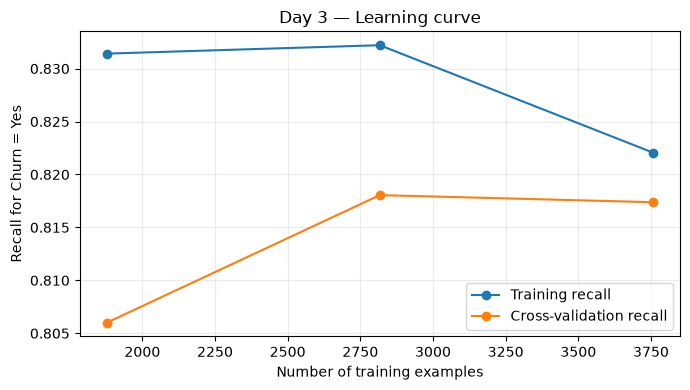

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training recall",
)
plt.plot(
    train_sizes,
    validation_scores.mean(axis=1),
    marker="o",
    label="Cross-validation recall",
)
plt.xlabel("Number of training examples")
plt.ylabel("Recall for Churn = Yes")
plt.title("Day 3 — Learning curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_DIR / "day3_learning_curve.png", dpi=140)
plt.show()

### Day 3 checkpoint

- Which parameters were selected for the champion?
- Is training recall much higher than cross-validation recall?
- Does validation recall improve as the training set grows?
- What might you try next if both training and validation recall are low?

**Milestone 3:** the tuned champion is saved as `models/churn_day3_tuned.joblib`, with CV results and learning-curve outputs in `reports/`.

# Day 4 — Feature engineering, feature selection and ensembles

**Goal:** add a small set of business-interpretable features and compare ensemble models against the tuned champion.

The new features are created from existing columns:
- `tenure_group`: broad customer-tenure bands;
- `average_charge_per_month`: total charges divided by tenure;
- `is_month_to_month`: whether the contract is month-to-month;
- `uses_electronic_check`: whether the customer uses electronic check.

Feature selection is fitted inside the pipeline. This ensures the selected features are determined independently within each training fold.

### 4.1 Create additional customer features

In [43]:
def add_customer_features(input_frame):
    """Add simple, explainable features without using the target column."""
    engineered = input_frame.copy()

    if "tenure" in engineered.columns:
        tenure = pd.to_numeric(engineered["tenure"], errors="coerce")
        engineered["tenure_group"] = pd.cut(
            tenure,
            bins=[-1, 12, 24, 48, 72],
            labels=["0-12", "13-24", "25-48", "49-72"],
        ).astype("object")

    if {"TotalCharges", "tenure"}.issubset(engineered.columns):
        total = pd.to_numeric(engineered["TotalCharges"], errors="coerce")
        tenure = pd.to_numeric(engineered["tenure"], errors="coerce").replace(0, np.nan)
        engineered["average_charge_per_month"] = total / tenure

    if "Contract" in engineered.columns:
        engineered["is_month_to_month"] = (
            engineered["Contract"] == "Month-to-month"
        ).astype(int)

    if "PaymentMethod" in engineered.columns:
        engineered["uses_electronic_check"] = (
            engineered["PaymentMethod"] == "Electronic check"
        ).astype(int)

    return engineered


X_train_day4 = add_customer_features(X_train)
X_test_day4 = add_customer_features(X_test)

print("Original feature count:", X_train.shape[1])
print("Feature count after engineering:", X_train_day4.shape[1])
display(X_train_day4.head())

Original feature count: 19
Feature count after engineering: 23


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,average_charge_per_month,is_month_to_month,uses_electronic_check
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,...,Yes,Month-to-month,No,Electronic check,49.20,1701.65,25-48,48.618571,1,1
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,...,No,Month-to-month,No,Mailed check,75.10,1151.55,13-24,76.770000,1,0
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,...,No,Two year,No,Mailed check,40.55,590.35,13-24,45.411538,0,0
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,...,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,25-48,73.296154,0,0
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,...,No,Month-to-month,No,Electronic check,44.55,44.55,0-12,44.550000,1,1


### 4.2 Build a feature-selection pipeline

In [44]:
def make_day4_pipeline(input_frame, estimator):
    """Preprocess, select the top 30 transformed features, then fit the estimator.

    Telco's one-hot encoded feature set contains more than 30 columns.
    Preprocessing and feature selection remain inside the Pipeline so they
    are refitted separately within each cross-validation fold.
    """
    return Pipeline(steps=[
        ("preprocess", make_preprocessor(input_frame)),
        ("feature_selection", SelectKBest(score_func=f_classif, k=30)),
        ("model", estimator),
    ])


print("Day 4 pipeline helper is ready.")

Day 4 pipeline helper is ready.


### 4.3 Define ensemble candidates

In [45]:
day4_candidates = {
    "Random Forest + SelectKBest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

# XGBoost is optional. The Random Forest experiment still runs if it is absent.
try:
    from xgboost import XGBClassifier

    day4_candidates["XGBoost + SelectKBest"] = XGBClassifier(
        n_estimators=250,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    print("XGBoost is available.")
except ImportError:
    print("XGBoost is not installed. Random Forest will run; install xgboost to add the boosting candidate.")

print("Candidates:", list(day4_candidates))

XGBoost is not installed. Random Forest will run; install xgboost to add the boosting candidate.
Candidates: ['Random Forest + SelectKBest']


### 4.4 Compare ensembles using cross-validation

In [46]:
day4_fitted = {}
day4_rows = []

for model_name, estimator in day4_candidates.items():
    print(f"Cross-validating {model_name} ...")
    candidate_pipeline = make_day4_pipeline(X_train_day4, estimator)

    cv_recall_scores = cross_val_score(
        candidate_pipeline,
        X_train_day4,
        y_train,
        scoring="recall",
        cv=cv_strategy,
        n_jobs=-1,
    )

    # Fit the final candidate on all training rows after CV evaluation.
    candidate_pipeline.fit(X_train_day4, y_train)
    day4_fitted[model_name] = candidate_pipeline

    test_metrics = evaluate_classifier(
        f"Day 4 — {model_name}",
        candidate_pipeline,
        X_test_day4,
        y_test,
        show_details=False,
    )
    test_metrics["CV_Recall_Mean"] = cv_recall_scores.mean()
    test_metrics["CV_Recall_Std"] = cv_recall_scores.std()
    day4_rows.append(test_metrics)

day4_comparison = pd.DataFrame(day4_rows).sort_values(
    "CV_Recall_Mean", ascending=False
)
display(day4_comparison)
day4_comparison.to_csv(REPORT_DIR / "day4_ensemble_comparison.csv", index=False)

Cross-validating Random Forest + SelectKBest ...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall_Mean,CV_Recall_Std
0,Day 4 — Random Forest + SelectKBest,0.753016,0.527311,0.671123,0.590588,0.823823,0.718397,0.00611


### 4.5 Compare the Day 4 candidates with the Day 3 champion

In [47]:
# The Day 3 champion uses the original input columns.
# Day 4 candidates use the engineered input columns.
# Both are evaluated on the same held-out customer rows.
day3_reference_metrics = evaluate_classifier(
    f"Day 3 champion — {day3_champion_name}",
    day3_champion,
    X_test,
    y_test,
    show_details=False,
)

comparison_rows = [{
    **day3_reference_metrics,
    "CV_Recall_Mean": np.nan,
    "CV_Recall_Std": np.nan,
}]
comparison_rows.extend(day4_rows)

day4_vs_day3 = pd.DataFrame(comparison_rows)
display(day4_vs_day3)
day4_vs_day3.to_csv(REPORT_DIR / "day4_vs_day3_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall_Mean,CV_Recall_Std
0,Day 3 champion — SVM,0.723918,0.487844,0.804813,0.607467,0.832935,NaN,NaN
1,Day 4 — Random Forest + SelectKBest,0.753016,0.527311,0.671123,0.590588,0.823823,0.718397,0.00611


### 4.6 Select and persist the Day 4 champion

In [48]:
# Champion promotion is based on training-only cross-validation recall.
day4_champion_name = day4_comparison.iloc[0]["Model"]
day4_champion = day4_fitted[day4_champion_name]

day4_champion_path = MODEL_DIR / "churn_day4_champion.joblib"
joblib.dump(day4_champion, day4_champion_path)

print("Day 4 champion:", day4_champion_name)
print("Mean CV recall:", round(day4_comparison.iloc[0]["CV_Recall_Mean"], 4))
print("Saved:", day4_champion_path)

# Final held-out test evaluation for the promoted Day 4 model.
day4_final_metrics = evaluate_classifier(
    f"Day 4 champion — {day4_champion_name}",
    day4_champion,
    X_test_day4,
    y_test,
)

KeyError: 'Day 4 — Random Forest + SelectKBest'

### Day 4 checkpoint

- Which engineered feature might be useful to the retention team, and why?
- Did feature selection improve the result compared with the Day 3 champion?
- Is the Day 4 champion selected using cross-validation rather than test-set performance?
- What additional checks would be needed before replacing a model in a live service?

**Milestone 4:** the Day 4 champion is saved as `models/churn_day4_champion.joblib`.

# Final project summary

The notebook has now produced a sequence of model artifacts:

| Increment | Artifact | Purpose |
|---|---|---|
| Day 1 | `churn_day1_baseline.joblib` | Initial baseline pipeline |
| Day 2 | `churn_day2_champion.joblib` | Best Day 2 candidate by CV recall |
| Day 3 | `churn_day3_tuned.joblib` | Tuned champion selected by CV recall |
| Day 4 | `churn_day4_champion.joblib` | Feature-engineered ensemble champion |

The comparison CSV files and learning-curve outputs are stored in `reports/`.

## What champion means here

A **candidate** is a model being evaluated. The **champion** is the current preferred model according to the agreed selection metric—in this project, mean cross-validation recall for the churn class. A new candidate can replace the champion only when its validation evidence supports the change.

The hold-out test set is kept separate from model selection. It is used to report final performance after a model has been selected.

## What this project covers—and what comes next

This project establishes ML engineering foundations: reusable preprocessing pipelines, repeatable evaluation, cross-validation, model comparison, tuning, feature engineering, and saved model artifacts.

It is not yet a complete production MLOps platform. Later increments can add experiment tracking, a model registry, automated tests, API deployment, CI/CD, monitoring, drift detection, and controlled retraining.

## Git workflow

From the RetailMind project root:

```bash
git add notebooks/RetailMind_Churn_Days_1_to_4.ipynb README.md requirements.txt
git add reports/
git commit -m "Build churn prediction pipeline through Day 4"
git push
```

Avoid committing the raw Kaggle dataset unless repository policy and dataset licensing explicitly permit it. Model artifacts can also be large; decide whether to track them in Git or use a model-artifact store.